# 04 | PLSA retrieval-scoring investigation

This experiment compares two ways of ranking documents with the same fitted PLSA model: cosine similarity between document-topic distributions, and query log-likelihood under the PLSA word model. TF-IDF/VSM and LSI provide reference rankings.

We use the six-category subset from the original scoring investigation, a stratified 75/25 train/test split, and a fixed PLSA topic count of K=6. Holding the corpus, fitted model, query set, and test candidates fixed lets us focus on how the scoring rule changes retrieval. The next study examines validation-based tuning and background smoothing.


## 1. Settings and imports

The experiment reads the shared processed corpus, then selects the six source categories below. Outputs are written to a fixed folder and replaced when this notebook is run again.


In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr

REPOSITORY_ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from src.evaluation import evaluate_ranked_retrieval
from src.lsi import fit_lsi
from src.plsa_model import train_plsa_restarts
from src.retrieval import cosine_scores, plsa_query_log_likelihood
from src.text_processing import load_nlp, preprocess_texts
from src.tfidf import fit_tfidf

SEED = 42
TEST_SIZE = 0.25
K = 6
N_RESTARTS = 5
MAX_ITER = 100
TOLERANCE = 1e-4
MAX_FEATURES = 3000
MIN_DF = 3
MAX_DF = 0.90
RETRIEVAL_K = 10
FOLD_IN_ITERATIONS = 100
DATA_PATH = REPOSITORY_ROOT / 'data' / '20news_preprocessed.npz'
OUTPUT_DIR = REPOSITORY_ROOT / 'results' / 'retrieval_scoring_investigation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_CATEGORIES = [
    'comp.graphics', 'misc.forsale', 'rec.sport.baseball',
    'sci.med', 'sci.space', 'talk.politics.guns',
]
print(f'Repository: {REPOSITORY_ROOT.resolve()}')
print(f'Results folder: {OUTPUT_DIR.resolve()}')
print(f'Fixed PLSA topic count: K={K}')


Repository: F:\OneDrive\Academics\bits\IR\Project\Local
Results folder: F:\OneDrive\Academics\bits\IR\Project\Local\results\retrieval_scoring_investigation
Fixed PLSA topic count: K=6


## 2. Select the six-category corpus and fixed queries

The category labels are used to select documents, stratify the split, and define retrieval relevance. They are not passed to PLSA during training. Each selected category has one direct keyword query, matching the original scoring comparison.


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Missing {DATA_PATH}. Run src/preprocessing.ipynb first.')
with np.load(DATA_PATH, allow_pickle=False) as corpus:
    all_documents = corpus['documents'].tolist()
    all_labels = corpus['labels'].astype(np.int64, copy=False)
    all_category_names = corpus['category_names'].tolist()

missing_categories = sorted(set(SELECTED_CATEGORIES) - set(all_category_names))
if missing_categories:
    raise ValueError(f'Selected categories are absent from the corpus: {missing_categories}')
selected_ids = [all_category_names.index(name) for name in SELECTED_CATEGORIES]
selected_mask = np.isin(all_labels, selected_ids)
documents = [doc for doc, keep in zip(all_documents, selected_mask) if keep]
labels = all_labels[selected_mask]
category_names = list(SELECTED_CATEGORIES)
category_to_label = {name: i for i, name in enumerate(category_names)}
label_remap = {source_id: category_to_label[name] for name, source_id in zip(SELECTED_CATEGORIES, selected_ids)}
labels = np.asarray([label_remap[int(label)] for label in labels], dtype=np.int64)

category_queries = {
    'comp.graphics': 'computer graphics rendering image pixels',
    'misc.forsale': 'for sale price shipping offer',
    'rec.sport.baseball': 'baseball players team season game',
    'sci.med': 'medical doctor disease treatment health',
    'sci.space': 'space NASA spacecraft orbit planet',
    'talk.politics.guns': 'gun control firearms second amendment',
}
if set(category_queries) != set(category_names):
    raise ValueError('Provide exactly one query for each selected category.')
category_counts = pd.DataFrame({
    'category': category_names,
    'documents': [int(np.count_nonzero(labels == i)) for i in range(len(category_names))],
})
print(f'Selected documents: {len(documents):,}; categories: {len(category_names)}')
display(category_counts)


Selected documents: 5,829; categories: 6


,category,documents
0,comp.graphics,973
1,misc.forsale,975
2,rec.sport.baseball,994
3,sci.med,990
4,sci.space,987
5,talk.politics.guns,910


## 3. Split the corpus and fit count features

The stratified split keeps each category represented in training and test data. The count vocabulary is fitted on training text only, then applied unchanged to the test documents and queries. Empty processed documents are excluded consistently from every method's test ranking.


In [3]:
docs_train, docs_test, y_train, y_test = train_test_split(
    documents, labels, test_size=TEST_SIZE, random_state=SEED, stratify=labels,
)
from sklearn.feature_extraction.text import CountVectorizer
count_vectorizer = CountVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=MAX_FEATURES, min_df=MIN_DF, max_df=MAX_DF,
    dtype=np.float64,
)
X_train = count_vectorizer.fit_transform(docs_train)
X_test = count_vectorizer.transform(docs_test)
vocabulary = count_vectorizer.get_feature_names_out()
nonempty_test = np.asarray([bool(text.strip()) for text in docs_test])

split_summary = pd.DataFrame({
    'split': ['train', 'test'],
    'documents': [len(docs_train), len(docs_test)],
    'empty_documents': [sum(not text.strip() for text in docs_train), int((~nonempty_test).sum())],
})
display(split_summary)
print('Count matrix shapes:', X_train.shape, X_test.shape)


,split,documents,empty_documents
0,train,4371,129
1,test,1458,43


Count matrix shapes: (4371, 3000) (1458, 3000)


## 4. Fit PLSA, TF-IDF, and LSI

PLSA is trained with five random initializations; the run with the highest training log-likelihood is retained. TF-IDF and LSI are fitted on training documents only. These fitted models are then held fixed for the comparison of scoring rules.


In [4]:
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=N_RESTARTS,
    max_iter=MAX_ITER, tol=TOLERANCE, base_seed=SEED,
)
theta_test = best_plsa.fold_in(X_test, max_iter=FOLD_IN_ITERATIONS)
restart_summary = pd.DataFrame([
    {'restart': i + 1, 'seed': SEED + i, 'iterations': model.n_iter_,
     'training_log_likelihood': float(ll), 'selected': model is best_plsa}
    for i, (model, ll) in enumerate(restart_runs)
])

tfidf_vectorizer, (X_train_tfidf, X_test_tfidf) = fit_tfidf(
    docs_train, docs_test, max_features=MAX_FEATURES,
    min_df=MIN_DF, max_df=MAX_DF,
)
lsi_model, (lsi_train, lsi_test) = fit_lsi(
    X_train_tfidf, X_test_tfidf, n_components=50, seed=SEED,
)
print('PLSA test mixtures:', theta_test.shape)
print('TF-IDF matrices:', X_train_tfidf.shape, X_test_tfidf.shape)
print('LSI matrices:', lsi_train.shape, lsi_test.shape)
display(restart_summary)


Restart 1: final training log-likelihood=-1829618.985, iterations=72
Restart 2: final training log-likelihood=-1828524.315, iterations=39
Restart 3: final training log-likelihood=-1822258.773, iterations=43
Restart 4: final training log-likelihood=-1823834.929, iterations=52
Restart 5: final training log-likelihood=-1831086.166, iterations=37
Selected best training likelihood: -1822258.773
PLSA test mixtures: (1458, 6)
TF-IDF matrices: (4371, 3000) (1458, 3000)
LSI matrices: (4371, 50) (1458, 50)


,restart,seed,iterations,training_log_likelihood,selected
0,1,42,72,-1.829619e+06,False
1,2,43,39,-1.828524e+06,False
2,3,44,43,-1.822259e+06,True
3,4,45,52,-1.823835e+06,False
4,5,46,37,-1.831086e+06,False


## 5. Compare the retrieval scoring rules

For each query, the same non-empty test documents are ranked by all four methods:

- **PLSA cosine:** cosine similarity between the query's folded-in topic mixture and each document's topic mixture.
- **PLSA query likelihood:** the sum of query-term counts times log P(word | document), where P(word | document) is derived from the same PLSA topic distributions. A small numerical floor prevents taking log(0); no background-word mixture is used here.
- **TF-IDF/VSM and LSI:** cosine similarity in their respective vector spaces.

We report Precision@10, Recall@10, AP@10, and NDCG@10 per query, then average across the six queries. We also measure how often the two PLSA scorers return the same top-10 documents and how similar their full rankings are.


In [5]:
query_nlp = load_nlp()
y_test_eval = y_test[nonempty_test]
theta_test_eval = theta_test[nonempty_test]
tfidf_test_eval = X_test_tfidf[nonempty_test]
lsi_test_eval = lsi_test[nonempty_test]

retrieval_rows = []
score_agreement_rows = []
rank_orders_by_query = {}
for category, query_text in category_queries.items():
    target_label = category_to_label[category]
    processed_query = preprocess_texts([query_text], nlp=query_nlp)[0]
    query_counts = count_vectorizer.transform([processed_query]).astype(np.float64)
    query_tfidf = tfidf_vectorizer.transform([processed_query])
    query_lsi = lsi_model.transform(query_tfidf)
    query_theta = best_plsa.fold_in(query_counts, max_iter=FOLD_IN_ITERATIONS)

    method_scores = {
        'TF-IDF/VSM': cosine_scores(query_tfidf, tfidf_test_eval),
        'LSI': cosine_scores(query_lsi, lsi_test_eval),
        'PLSA cosine': cosine_scores(query_theta, theta_test_eval),
        'PLSA query likelihood': plsa_query_log_likelihood(
            query_counts, theta_test_eval, best_plsa.phi_, smoothing=1e-10,
        ),
    }
    rank_orders_by_query[category] = {
        method: np.argsort(scores)[::-1] for method, scores in method_scores.items()
    }
    for method, scores in method_scores.items():
        metrics = evaluate_ranked_retrieval(
            scores, y_test_eval, target_label, k=RETRIEVAL_K,
        )
        retrieval_rows.append({
            'query_category': category, 'query_text': query_text,
            'method': method,
            'Precision@10': metrics['Precision@k'],
            'Recall@10': metrics['Recall@k'],
            'AP@10': metrics['AP@k'], 'NDCG@10': metrics['NDCG@k'],
            'relevant_test_documents': int(np.count_nonzero(y_test_eval == target_label)),
        })

    cosine_order = rank_orders_by_query[category]['PLSA cosine']
    likelihood_order = rank_orders_by_query[category]['PLSA query likelihood']
    top_cosine = set(cosine_order[:RETRIEVAL_K])
    top_likelihood = set(likelihood_order[:RETRIEVAL_K])
    rho = spearmanr(method_scores['PLSA cosine'], method_scores['PLSA query likelihood']).statistic
    score_agreement_rows.append({
        'query_category': category,
        'top10_overlap_count': len(top_cosine & top_likelihood),
        'top10_overlap_fraction': len(top_cosine & top_likelihood) / RETRIEVAL_K,
        'spearman_rank_correlation': float(rho),
    })

retrieval_metrics = pd.DataFrame(retrieval_rows)
mean_metrics = retrieval_metrics.groupby('method', sort=False)[
    ['Precision@10', 'Recall@10', 'AP@10', 'NDCG@10']
].mean().rename(columns={'AP@10': 'MAP@10'})
score_agreement = pd.DataFrame(score_agreement_rows)
print('Per-query retrieval metrics:')
display(retrieval_metrics.round(4))
print('Macro-average retrieval metrics across the six queries:')
display(mean_metrics.round(4))
print('Agreement between the two PLSA scoring rules:')
display(score_agreement.round(4))


Per-query retrieval metrics:


,query_category,query_text,method,Precision@10,Recall@10,AP@10,NDCG@10,relevant_test_documents
0,comp.graphics,computer graphics rendering image pixels,TF-IDF/VSM,0.9,0.0377,0.8354,0.9149,239
1,comp.graphics,computer graphics rendering image pixels,LSI,0.7,0.0293,0.5881,0.7574,239
2,comp.graphics,computer graphics rendering image pixels,PLSA cosine,0.9,0.0377,0.7571,0.8611,239
3,comp.graphics,computer graphics rendering image pixels,PLSA query likelihood,1.0,0.0418,1.0000,1.0000,239
4,misc.forsale,for sale price shipping offer,TF-IDF/VSM,0.9,0.0375,0.8354,0.9149,240
5,misc.forsale,for sale price shipping offer,LSI,0.9,0.0375,0.8789,0.9306,240
6,misc.forsale,for sale price shipping offer,PLSA cosine,0.9,0.0375,0.8354,0.9149,240
7,misc.forsale,for sale price shipping offer,PLSA query likelihood,1.0,0.0417,1.0000,1.0000,240
8,rec.sport.baseball,baseball players team season game,TF-IDF/VSM,1.0,0.0424,1.0000,1.0000,236
9,rec.sport.baseball,baseball players team season game,LSI,1.0,0.0424,1.0000,1.0000,236


Macro-average retrieval metrics across the six queries:


,Precision@10,Recall@10,MAP@10,NDCG@10
method,,,,
TF-IDF/VSM,0.9667,0.0410,0.9451,0.9716
LSI,0.9333,0.0397,0.9112,0.9480
PLSA cosine,0.8333,0.0352,0.6885,0.7877
PLSA query likelihood,0.8667,0.0366,0.7879,0.8587


Agreement between the two PLSA scoring rules:


,query_category,top10_overlap_count,top10_overlap_fraction,spearman_rank_correlation
0,comp.graphics,3,0.3,0.9065
1,misc.forsale,5,0.5,0.9321
2,rec.sport.baseball,2,0.2,0.8748
3,sci.med,10,1.0,0.8659
4,sci.space,9,0.9,0.8615
5,talk.politics.guns,7,0.7,0.9161


## 6. Visualize metric and ranking differences

The first chart compares macro-averaged retrieval quality. The second shows per-query overlap between the PLSA cosine and query-likelihood top-10 results. A low overlap means the scoring rules surface different documents, even though they use the same fitted PLSA model.


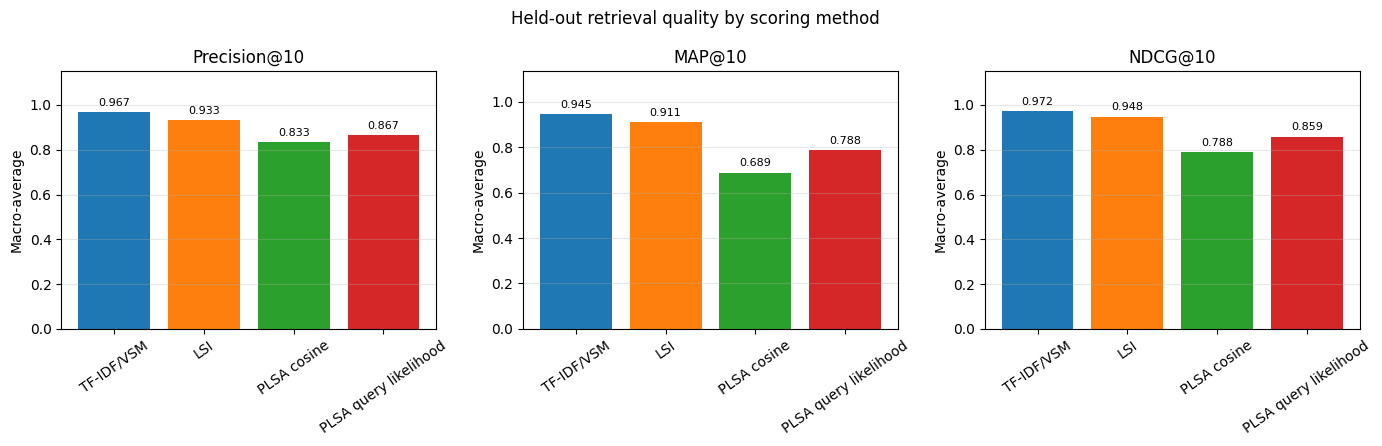

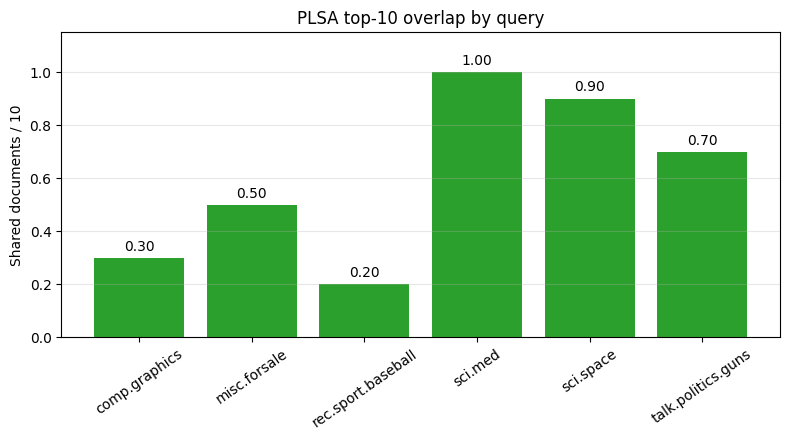

In [9]:
plot_metrics = ['Precision@10', 'MAP@10', 'NDCG@10']
metrics_fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric in zip(axes, plot_metrics):
    values = mean_metrics[metric]
    bars = ax.bar(values.index, values.to_numpy(), color=plt.cm.tab10.colors[:len(values)])
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.set_title(metric)
    ax.set_ylabel('Macro-average')
    ax.set_ylim(0, min(1.15, max(0.1, float(values.max()) * 1.2)))
    ax.tick_params(axis='x', rotation=35)
    ax.grid(axis='y', alpha=0.3)
metrics_fig.suptitle('Held-out retrieval quality by scoring method')
metrics_fig.tight_layout()
# display(metrics_fig)

overlap_fig, overlap_ax = plt.subplots(figsize=(8, 4.5))
overlap_bars = overlap_ax.bar(
    score_agreement['query_category'], score_agreement['top10_overlap_fraction'],
    color=plt.cm.tab10.colors[2],
)
overlap_ax.bar_label(overlap_bars, fmt='%.2f', padding=3)
overlap_ax.set(title='PLSA top-10 overlap by query', ylabel='Shared documents / 10', ylim=(0, 1.15))
overlap_ax.tick_params(axis='x', rotation=35)
overlap_ax.grid(axis='y', alpha=0.3)
overlap_fig.tight_layout()
# display(overlap_fig)


## 7. Inspect which categories drive the differences

The per-query table keeps category-specific behavior visible. The difference column is positive when query likelihood has higher AP@10 than PLSA cosine for that category query.


In [7]:
plsa_ap = retrieval_metrics[retrieval_metrics['method'].isin(['PLSA cosine', 'PLSA query likelihood'])].pivot(
    index='query_category', columns='method', values='AP@10',
)
plsa_ap['query_likelihood_minus_cosine_AP@10'] = plsa_ap['PLSA query likelihood'] - plsa_ap['PLSA cosine']
display(plsa_ap.round(4))


method,PLSA cosine,PLSA query likelihood,query_likelihood_minus_cosine_AP@10
query_category,,,
comp.graphics,0.7571,1.0000,0.2429
misc.forsale,0.8354,1.0000,0.1646
rec.sport.baseball,1.0000,1.0000,0.0000
sci.med,0.7071,0.8354,0.1283
sci.space,0.6378,0.6711,0.0333
talk.politics.guns,0.1938,0.2206,0.0268


## 8. Save outputs

The per-query and macro-average metrics, scorer-agreement tables, figures, and run configuration are saved in `results/retrieval_scoring_investigation/`. Rerunning this notebook replaces the previous outputs for this experiment.


In [8]:
retrieval_metrics.to_csv(OUTPUT_DIR / 'retrieval_metrics_by_query.csv', index=False)
mean_metrics.to_csv(OUTPUT_DIR / 'retrieval_metrics_macro_average.csv')
score_agreement.to_csv(OUTPUT_DIR / 'plsa_scoring_agreement_by_query.csv', index=False)
plsa_ap.to_csv(OUTPUT_DIR / 'plsa_ap_difference_by_query.csv')
restart_summary.to_csv(OUTPUT_DIR / 'plsa_restart_summary.csv', index=False)
metrics_fig.savefig(OUTPUT_DIR / 'retrieval_metrics_comparison.png', dpi=160, bbox_inches='tight')
overlap_fig.savefig(OUTPUT_DIR / 'plsa_top10_overlap.png', dpi=160, bbox_inches='tight')

configuration = {
    'experiment': 'PLSA retrieval-scoring investigation',
    'selected_categories': SELECTED_CATEGORIES,
    'seed': SEED, 'test_size': TEST_SIZE, 'n_topics': K,
    'n_restarts': N_RESTARTS, 'max_iter': MAX_ITER, 'tolerance': TOLERANCE,
    'max_features': MAX_FEATURES, 'min_df': MIN_DF, 'max_df': MAX_DF,
    'retrieval_k': RETRIEVAL_K,
    'plsa_scoring_methods': ['cosine similarity in topic space', 'unsmoothed query log-likelihood with numerical floor'],
    'query_set': category_queries,
    'documents': len(documents),
}
with (OUTPUT_DIR / 'configuration.json').open('w', encoding='utf-8') as handle:
    json.dump(configuration, handle, indent=2)
print(f'Saved retrieval-scoring outputs to {OUTPUT_DIR.resolve()}')


Saved retrieval-scoring outputs to F:\OneDrive\Academics\bits\IR\Project\Local\results\retrieval_scoring_investigation
